In [1]:
pacman::p_load(dplyr,ggplot2,lubridate,ggridges,ggmap,patchwork,ggnewscale,
               RColorBrewer,trend,ggpmisc,boot)

In [2]:
species_codes = read.csv(file.path("../data","CC_plankton_200_2021_metadata_species.csv")) %>%
    dplyr::mutate(SPEC_CODE_MUT=dplyr::case_when(!is.na(as.numeric(as.character(SPEC_CODE))) ~ 
                                                 as.character(as.numeric(as.character(SPEC_CODE))),
                                                 TRUE ~ as.character(SPEC_CODE)))

plankton_metadata = read.csv("../data/CC_plankton_200_2021_metadata_species.csv")
plankton_counts = read.csv("../data/cc_plankton_2020_202307.csv")
merged_pkton = plankton_counts %>% dplyr::left_join(plankton_metadata)

paired_data = read.csv(file.path("../data","cc_plankton_2000_2021.csv")) %>%
    dplyr::mutate(SPEC_CODE = as.character(SPEC_CODE)) %>%
    dplyr::mutate(SPEC_CODE_MUT=dplyr::case_when(!is.na(as.numeric(as.character(SPEC_CODE))) ~ 
                                                 as.character(as.numeric(as.character(SPEC_CODE))),
                                                 TRUE ~ as.character(SPEC_CODE)))%>%
    dplyr::left_join(species_codes,by=c("SPEC_CODE_MUT")) %>%
    dplyr::bind_rows(merged_pkton) %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV,format='%d-%b-%Y %H:%M:%S')) %>%
    dplyr::filter(!(trimws(GROUP_ID) %in% c("COPEPOD",
                                             "OTHER (ZOO)",
                                             "BARNACLE"))) 

Warning message:
“There were 2 warnings in `dplyr::mutate()`.
The first warning was:
ℹ In argument: `SPEC_CODE_MUT = dplyr::case_when(...)`.
Caused by warning:
! NAs introduced by coercion
ℹ Run `dplyr::last_dplyr_warnings()` to see the 1 remaining warning.”
Joining with `by = join_by(SPEC_CODE)`
Warning message:
“There were 2 warnings in `dplyr::mutate()`.
The first warning was:
ℹ In argument: `SPEC_CODE_MUT = dplyr::case_when(...)`.
Caused by warning:
! NAs introduced by coercion
ℹ Run `dplyr::last_dplyr_warnings()` to see the 1 remaining warning.”


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  and UNIT_CODE.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, and DESCR.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, and
  DESCR.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, and GROUP_ID.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by regime, DESCR, and GROUP_ID.
ℹ Output is grouped by regime and DESCR.
ℹ Use `summarise(.groups = "drop_last")` to silence this

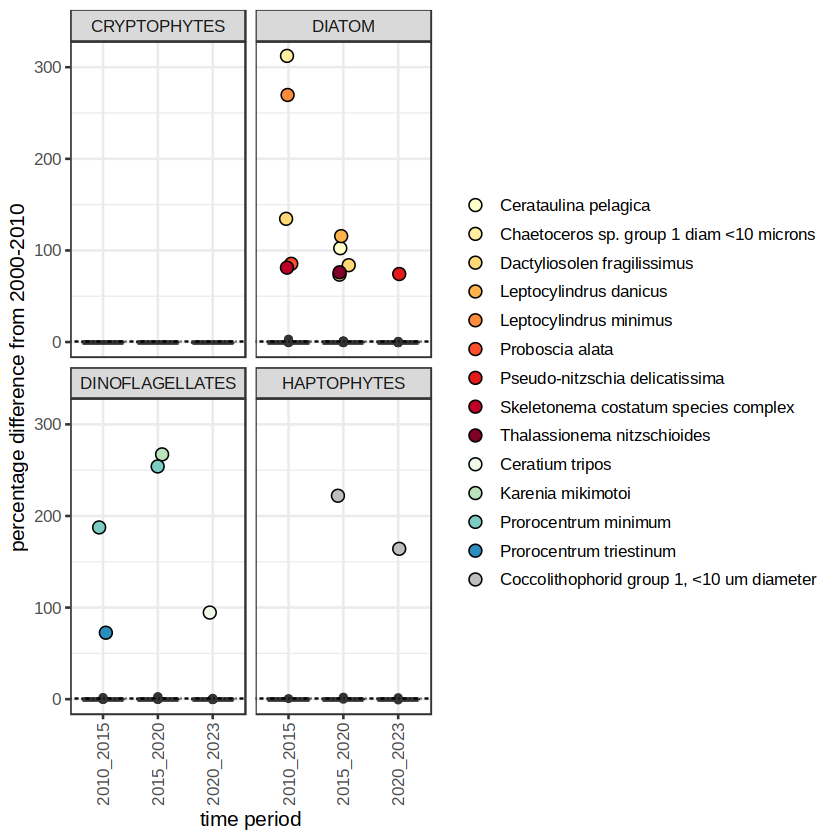

In [3]:
infill_dates = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES",
                                        "CRYPTOPHYTES")) %>%
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date"),names_from="DESCR",values_from="Group_Ct")

infill_dates[is.na(infill_dates)]=0

group_connect = paired_data %>% dplyr::select(GROUP_ID,DESCR) %>%
    dplyr::mutate(DESCR=trimws(DESCR)) %>%
    dplyr::distinct() %>% dplyr::filter(!is.na(GROUP_ID) & !is.na(DESCR))

for_plotting = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::mutate(GROUP_ID = case_when(grepl("DIATOM",GROUP_ID)~"DIATOM",
                                      TRUE~GROUP_ID)) %>%
    dplyr::mutate(Year = year(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                 Month = month(as.Date(Date,format='%d-%b-%Y %H:%M:%S'))) %>%
    dplyr::mutate(regime = case_when(Year > 2020 ~ "2020_2023",
                                     Year > 2015 ~ "2015_2020",
                                     Year > 2010 ~ "2010_2015",
                                    TRUE ~"early")) %>%
    dplyr::group_by(regime,DESCR,GROUP_ID) %>% dplyr::summarize(meanCt = mean(Group_Ct)) %>%
    tidyr::pivot_wider(id_cols=c("DESCR","GROUP_ID"),names_from="regime",
                       values_from="meanCt")%>%
    tidyr::pivot_longer(cols=!(starts_with("GROUP_ID")|starts_with("DESCR")|starts_with("early")),
                       names_to="regime",
                       values_to="value") %>%
    dplyr::mutate(labeled_pts = case_when(((value)-(early))/(early+0.01)> 0.7~DESCR,
                                          TRUE~NA))

seasonal_shifts = ggplot(for_plotting)+
    geom_boxplot(aes(x=regime,y=((value)-(early))/(early+0.01),group=paste0(GROUP_ID,regime)))+new_scale_fill() + 
    geom_jitter(data=for_plotting %>% dplyr::filter(!is.na(labeled_pts)) %>%
               dplyr::arrange(GROUP_ID) %>% 
               dplyr::mutate(labeled_pts=factor(labeled_pts,levels=(for_plotting %>% 
                                                dplyr::distinct(labeled_pts,.keep_all=TRUE) %>%
                                                dplyr::filter(!is.na(labeled_pts)) %>%
               dplyr::arrange(GROUP_ID))$labeled_pts)),
               aes(x=regime,y=((value)-(early))/(early+0.01)*100,group=paste0(regime,GROUP_ID),
                   fill=labeled_pts), na.rm=TRUE,pch=21,size=3,width=0.1,height=0)+ 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + facet_wrap(~GROUP_ID,nrow=3) + 
    geom_hline(aes(yintercept=0.75),linetype="dotdash") + theme_bw(base_size=12) + 
    ylab("percentage difference from 2000-2010")+ 
    scale_fill_manual(values=c(brewer.pal(9, "YlOrRd"),
                               brewer.pal(4,"GnBu"),"gray"),name="") + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + xlab("time period")

seasonal_shifts

In [4]:
for_prob_test = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR"))%>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|
                                 grepl("Emiliania",DESCR)|
                                 grepl("Isochrysis",DESCR)~"Isochrysidales",
                                 grepl("Prorocentru",DESCR)~"Prorocentrales",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales",
                                 grepl("nitzschia",tolower(DESCR))|
                                 grepl("Bacillaria",DESCR)|
                                 grepl("Cylindrotheca",DESCR)|
                                 grepl("Fragilariopsis",DESCR)|
                                 grepl("Denticula",DESCR)~"Bacillariales",
                                 grepl("Guinardia",DESCR)|grepl("Proboscia",DESCR)|
                                 grepl("Dactyliosolen",DESCR)|grepl("Rhizosolenia",DESCR)~
                                 "Rhizosoleniales",
                                 grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)~
                                 "Prymesiophyte",
                                 grepl("Hemiaulus",DESCR)|grepl("Eucampia",DESCR)|
                                 grepl("Cerataulina",DESCR)~
                                 "Hemiaulales",
                                 grepl("Coscino",DESCR)~
                                 "Coscinodiscus",
                                 grepl("Gymnodinium",DESCR)|grepl("Gyrodinium",DESCR)|
                                 grepl("Karenia",DESCR)|grepl("Amphidinium",DESCR)|
                                 grepl("Akashiwo",DESCR)~
                                 "Gymnodiniales",
                                 grepl("Guinardia",DESCR)|grepl("Proboscia",DESCR)|
                                 grepl("Dactyliosolen",DESCR)|grepl("Rhizosolenia",DESCR)~
                                 "Rhizosoleniales",
                                 grepl("Thecate",DESCR)~
                                 "Suessiales",
                                 grepl("Gonyaulax",DESCR)|grepl("ceratium",tolower(DESCR))|
                                 grepl("Tripos",DESCR)~
                                 "Gonyaulacales",
                                 grepl("Chaetocero",DESCR)~"Chaetocerotales",
                                 grepl("Phaeo",DESCR)~
                                 "Phaeocystales")) %>%
    dplyr::group_by(type,Date) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type and Date.
ℹ Output is grouped by type.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(type, Date))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


In [5]:
## read in nutrient data
nutrient_data = read.csv(file.path("../data/nutrients/CC_wet_chemistry_2022_2023.csv"))%>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV,format="%Y-%m-%d")) %>%
    dplyr::bind_rows(read.csv(file.path("../data/nutrients/CC_wet_chemistry_2000_2021.csv"))%>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV,format='%d-%b-%Y %H:%M:%S')))

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 54 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 54 rows containing missing values or values outside the scale range
(`geom_point()`).”


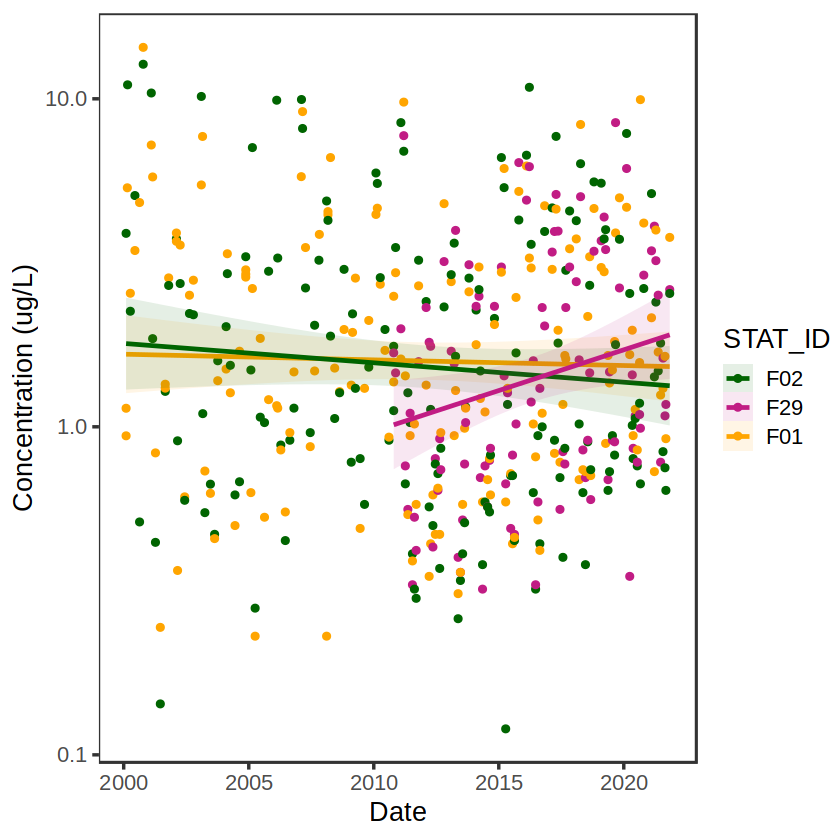

In [6]:
chlorophyll_by_station = ggplot(nutrient_data %>% dplyr::filter((PARAM_CODE=="CHLA")) %>%
    dplyr::filter(DEPTH<5)%>%dplyr::filter(STAT_ID%in%c("F01","F02","F29"))%>%
    dplyr::mutate(Category=case_when(PARAM_CODE %in% c("NO2","NO3","NO3+NO2")~"Nitrogen",
                                     PARAM_CODE %in% c("CHLA")~"Chlorophyll",
                                     TRUE~"Phosphorus")) %>%
    dplyr::mutate(Year = year(as.Date(STAT_ARRIV,format='%d-%b-%Y %H:%M:%S')),
                  Date=as.Date(STAT_ARRIV,format='%d-%b-%Y %H:%M:%S')))+
    #geom_line(aes(x=Date,y=FFU_RESULT,color=STAT_ID,group=PARAM_CODE),lwd=1.2) +
    geom_point(aes(x=Date,y=FFU_RESULT,color=STAT_ID),stat="identity") +  
    geom_smooth(aes(x=Date,y=FFU_RESULT,color=STAT_ID,fill=STAT_ID,group=paste0(STAT_ID,PARAM_CODE)),
                    method="lm",alpha=0.1) + 
    ylab("Concentration (ug/L)") + theme_test(base_size=16)+ scale_y_log10()+
    scale_color_manual(values=c("dark green","#C11C84","orange"),
                       breaks=c("F02","F29","F01"))+
    scale_fill_manual(values=c("dark green","#C11C84","orange"),
                       breaks=c("F02","F29","F01"))
chlorophyll_by_station

In [7]:
infill_dates_metaT = read.csv("../workflows/run_models/model_outputs_13/metaT_informed/ccb/model_output.csv")%>%
    dplyr::mutate(abund=case_when(abund<0~0,
                                  TRUE~abund)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(DateTime,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::filter(DateTimeForm>as.Date("2000-03-01",format="%Y-%m-%d"))%>%
    dplyr::group_by(DateTimeForm,taxon)%>%dplyr::summarize(abund=mean(abund))%>%
    dplyr::ungroup() %>%
    dplyr::group_by(taxon) %>%
    dplyr::mutate(z_score=(abund-mean(abund))/sd(abund)) %>%
    dplyr::mutate(taxon=case_when(taxon=="Chaetocerotophycidae"~"Chaetocerotales",
                                  taxon=="Leptocylindrales"~"Leptocylindrus",
                                  taxon=="Coscinodiscales"~"Coscinodiscus",
                                  TRUE~taxon))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by DateTimeForm and taxon.
ℹ Output is grouped by DateTimeForm.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(DateTimeForm, taxon))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


In [8]:
infill_dates_allometry = read.csv("../workflows/run_models/model_outputs_13/allometry/ccb/model_output.csv")%>%
    dplyr::mutate(abund=case_when(abund<0~0,
                                  TRUE~abund)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(DateTime,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::filter(DateTimeForm>as.Date("2000-03-01",format="%Y-%m-%d"))%>%
    dplyr::group_by(DateTimeForm,taxon)%>%dplyr::summarize(abund=mean(abund))%>%
    dplyr::ungroup() %>%
    dplyr::group_by(taxon) %>%
    dplyr::mutate(z_score=(abund-mean(abund))/sd(abund)) %>%
    dplyr::mutate(taxon=case_when(taxon=="Chaetocerotophycidae"~"Chaetocerotales",
                                  taxon=="Leptocylindrales"~"Leptocylindrus",
                                  taxon=="Coscinodiscales"~"Coscinodiscus",
                                  TRUE~taxon))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by DateTimeForm and taxon.
ℹ Output is grouped by DateTimeForm.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(DateTimeForm, taxon))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


In [9]:
summarized_metaT = infill_dates_metaT %>% dplyr::group_by(DateTimeForm) %>% 
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))) %>%
    dplyr::summarize(total_abund_metaT=sum(abund))
summarized_allometry = infill_dates_allometry %>% dplyr::group_by(DateTimeForm) %>% 
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))) %>%
    dplyr::summarize(total_abund_allometry=sum(abund))

In [10]:
chlorophyll_data = nutrient_data %>% dplyr::filter((PARAM_CODE=="CHLA")) %>%
    dplyr::filter(DEPTH<5)%>%dplyr::filter(STAT_ID%in%c("F01","F02","F29"))%>%
    dplyr::mutate(Category=case_when(PARAM_CODE %in% c("NO2","NO3","NO3+NO2")~"Nitrogen",
                                     PARAM_CODE %in% c("CHLA")~"Chlorophyll",
                                     TRUE~"Phosphorus")) %>%
    dplyr::mutate(Date=as.Date(Date,format='%Y-%m-%d')) %>% 
    dplyr::filter(STAT_ID=="F29") %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(Date, "%Y-%m"), "-01"))) %>%
    dplyr::group_by(DateTimeForm,Category) %>% dplyr::summarize(chlorophyll=mean(FFU_RESULT)) 

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by DateTimeForm and Category.
ℹ Output is grouped by DateTimeForm.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(DateTimeForm, Category))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


Joining with `by = join_by(DateTimeForm)`
Joining with `by = join_by(DateTimeForm)`
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


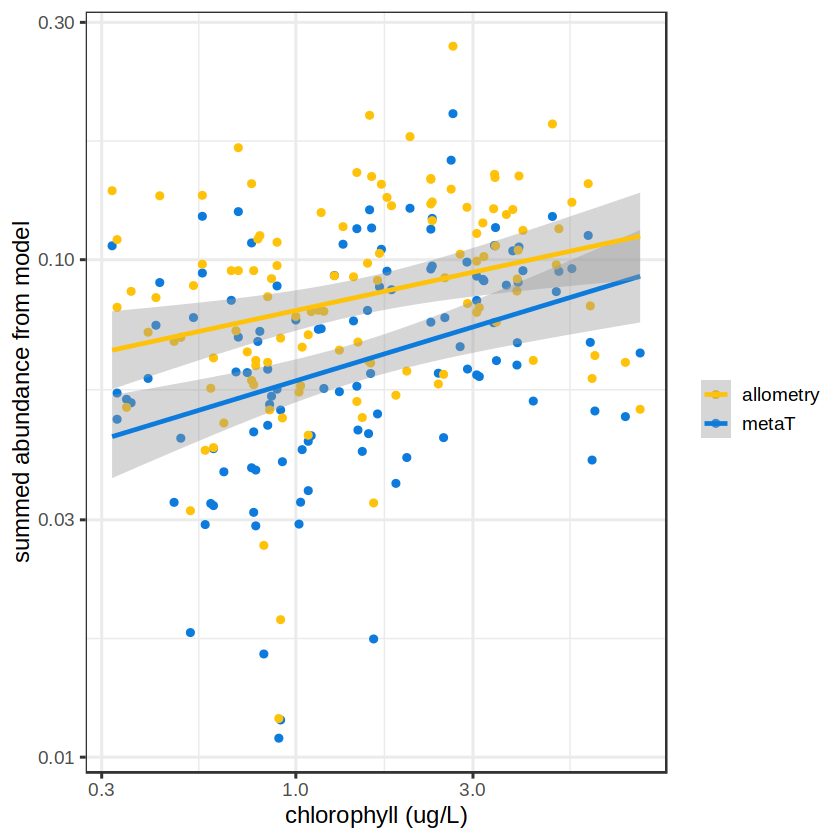

In [11]:
merged_w_chlorophyll = chlorophyll_data %>% dplyr::left_join(summarized_metaT) %>% 
    dplyr::left_join(summarized_allometry)

ggplot(merged_w_chlorophyll) +
    geom_point(aes(x=chlorophyll,y=total_abund_metaT,color="metaT"))+
    geom_point(aes(x=chlorophyll,y=total_abund_allometry,color="allometry")) +
    geom_smooth(aes(x=chlorophyll,y=total_abund_metaT,color="metaT"),
                method="lm")+
    geom_smooth(aes(x=chlorophyll,y=total_abund_allometry,
                    color="allometry"),method="lm") + theme_bw(base_size=14) + 
    xlab("chlorophyll (ug/L)") + ylab("summed abundance from model") +
    scale_y_log10() + scale_x_log10() + 
    scale_color_manual(values=c("#FFC20A","#0C7BDC"),name="") 

Joining with `by = join_by(DateTimeForm)`
Joining with `by = join_by(DateTimeForm)`
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


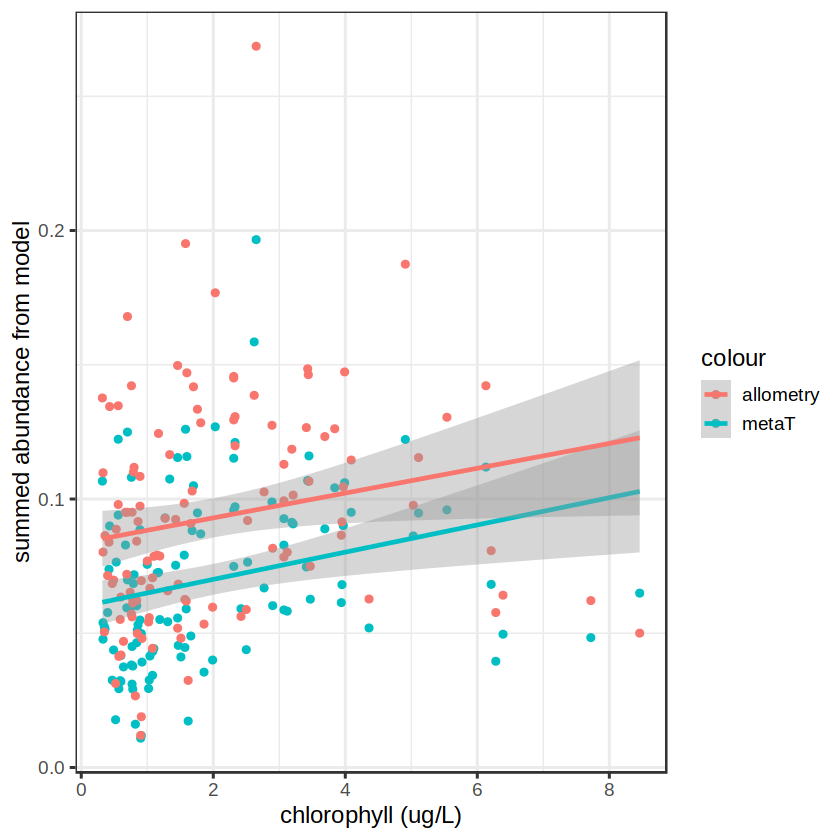

In [12]:
merged_w_chlorophyll = chlorophyll_data %>% dplyr::left_join(summarized_metaT) %>% 
    dplyr::left_join(summarized_allometry)

ggplot(merged_w_chlorophyll) +
    geom_point(aes(x=chlorophyll,y=total_abund_metaT,color="metaT"))+
    geom_point(aes(x=chlorophyll,y=total_abund_allometry,color="allometry")) +
    geom_smooth(aes(x=chlorophyll,y=total_abund_metaT,color="metaT"),
                method="lm")+
    geom_smooth(aes(x=chlorophyll,y=total_abund_allometry,
                    color="allometry"),method="lm") + theme_bw(base_size=14) + 
    xlab("chlorophyll (ug/L)") + ylab("summed abundance from model") 

In [13]:
summary(lm(formula = total_abund_metaT~chlorophyll,data=merged_w_chlorophyll))


Call:
lm(formula = total_abund_metaT ~ chlorophyll, data = merged_w_chlorophyll)

Residuals:
      Min        1Q    Median        3Q       Max 
-0.053577 -0.023186 -0.004377  0.019756  0.123242 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 0.059933   0.004540  13.201  < 2e-16 ***
chlorophyll 0.005069   0.001724   2.941  0.00396 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.0314 on 115 degrees of freedom
Multiple R-squared:  0.06993,	Adjusted R-squared:  0.06185 
F-statistic: 8.647 on 1 and 115 DF,  p-value: 0.003961


In [14]:
summary(lm(formula = total_abund_allometry~chlorophyll,data=merged_w_chlorophyll))


Call:
lm(formula = total_abund_allometry ~ chlorophyll, data = merged_w_chlorophyll)

Residuals:
      Min        1Q    Median        3Q       Max 
-0.075920 -0.029075 -0.003316  0.024532  0.172680 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 0.083724   0.005775  14.498   <2e-16 ***
chlorophyll 0.004620   0.002193   2.107   0.0373 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.03993 on 115 degrees of freedom
Multiple R-squared:  0.03717,	Adjusted R-squared:  0.0288 
F-statistic: 4.439 on 1 and 115 DF,  p-value: 0.03729


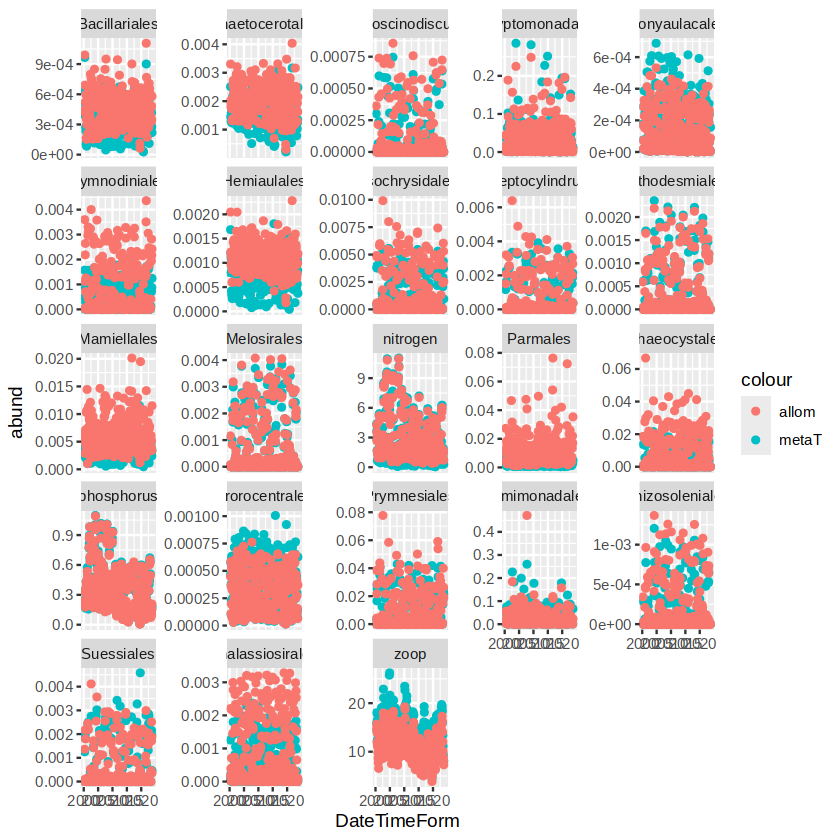

In [15]:
ggplot(infill_dates_metaT %>% dplyr::left_join(infill_dates_allometry %>% 
                                  dplyr::rename(c("allometry"="abund")),
                                 by=c("DateTimeForm","taxon")) %>%
    dplyr::mutate(percent_difference = (allometry-abund)/abund*100)) + 
    geom_point(aes(x=DateTimeForm,y=abund,color="metaT")) + 
    geom_point(aes(x=DateTimeForm,y=allometry,color="allom"))+
    facet_wrap(~taxon,scales="free_y")

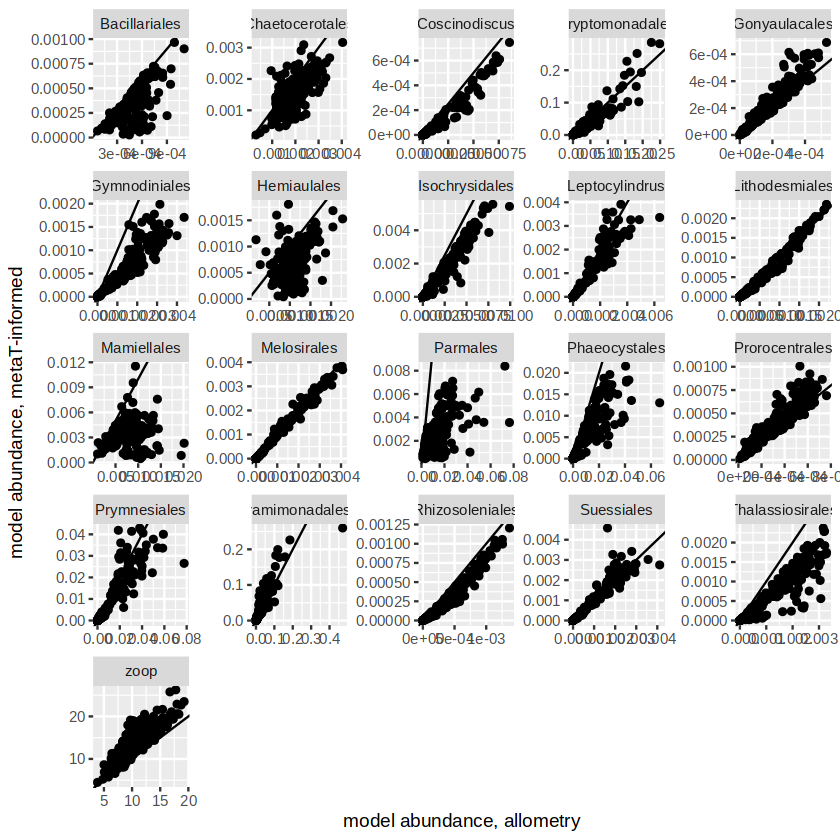

In [16]:
ggplot(infill_dates_metaT %>% dplyr::left_join(infill_dates_allometry %>% 
                                  dplyr::rename(c("allometry"="abund")),
                                 by=c("DateTimeForm","taxon")) %>%
    dplyr::filter(!(taxon%in%c("nitrogen","phosphorus"))) %>%
    dplyr::mutate(percent_difference = (allometry-abund)/abund*100)) + 
    geom_point(aes(x=allometry,y=abund)) +
    geom_abline(aes(intercept=0,slope=1))+
    facet_wrap(~taxon,scales="free") + ylab("model abundance, metaT-informed")+
    xlab("model abundance, allometry")

ggsave("../figures/supp_fig_1_to_1.pdf",width=12,height=12,units="in")

Saving 7 x 7 in image


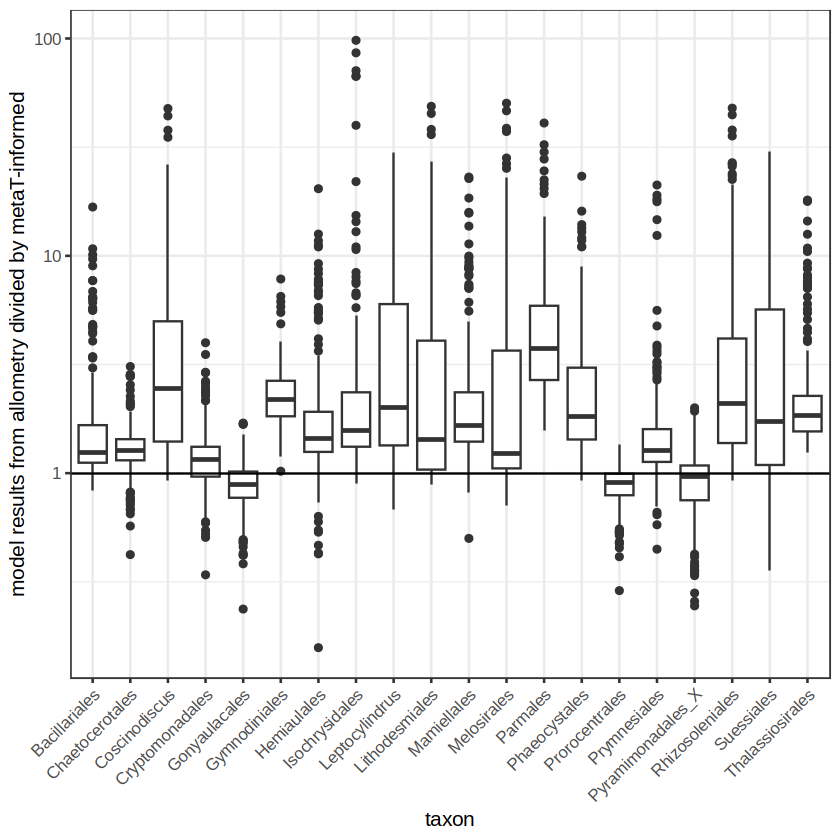

In [17]:
ggplot(infill_dates_metaT %>% dplyr::left_join(infill_dates_allometry %>% 
                                  dplyr::rename(c("allometry"="abund")),
                                 by=c("DateTimeForm","taxon")) %>%
    dplyr::mutate(percent_difference = allometry/abund) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=taxon,y=percent_difference))+
    geom_hline(aes(yintercept=1))+
    scale_y_log10() + 
    theme_bw(base_size=12)+ ylab("model results from allometry divided by metaT-informed") + 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

ggsave("../figures/ratio_metaT_allometry.pdf")

Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_line()`).”


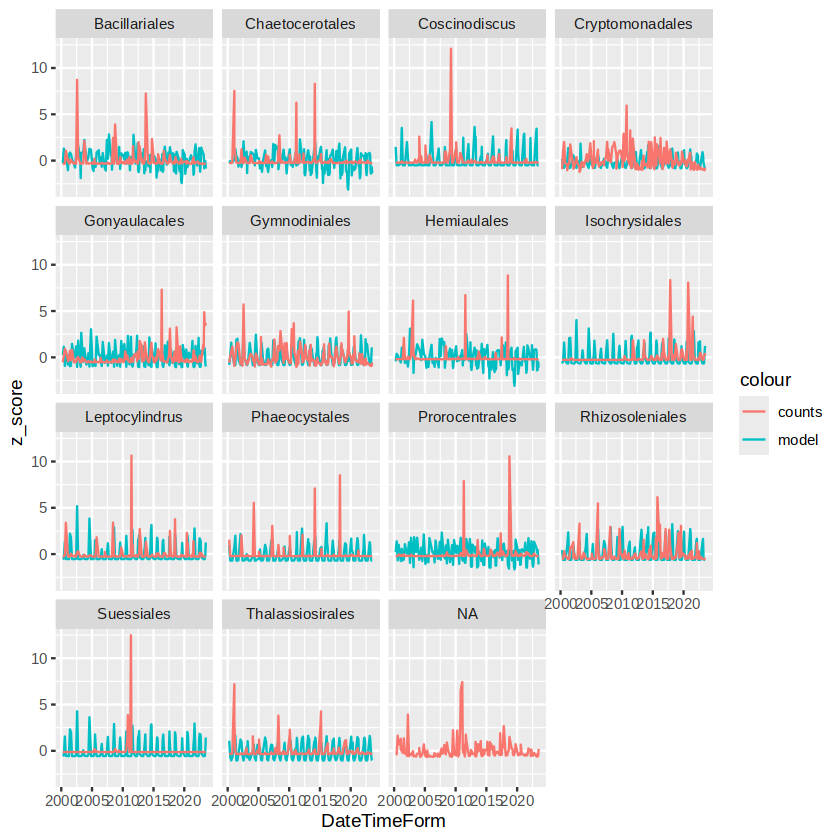

In [18]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_line(aes(x=DateTimeForm,y=z_score,color="model"))+
    geom_line(aes(x=DateTimeForm,y=z_score_obs,color="counts"))+
    facet_wrap(~type)

In [19]:
types_for_sum = intersect(for_prob_test$type,infill_dates_allometry$taxon)

In [20]:
summarized_for_test = for_prob_test %>% dplyr::filter(type%in%types_for_sum) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::group_by(DateTimeForm) %>% dplyr::summarize(summedgrpct=sum(Group_Ct)) %>%
    dplyr::mutate(dataset="counts") %>%
    dplyr::bind_rows(infill_dates_metaT %>% dplyr::group_by(DateTimeForm) %>%
       dplyr::summarize(summedgrpct=sum(abund)) %>% dplyr::mutate(dataset="metaT"))%>%
    dplyr::bind_rows(infill_dates_allometry %>% dplyr::group_by(DateTimeForm) %>%
       dplyr::summarize(summedgrpct=sum(abund)) %>% dplyr::mutate(dataset="allometry")) %>%
    dplyr::group_by(dataset) %>%
    dplyr::mutate(zscore = (summedgrpct-mean(summedgrpct))/sd(summedgrpct))

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 114 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 114 rows containing missing values or values outside the scale range
(`geom_point()`).”


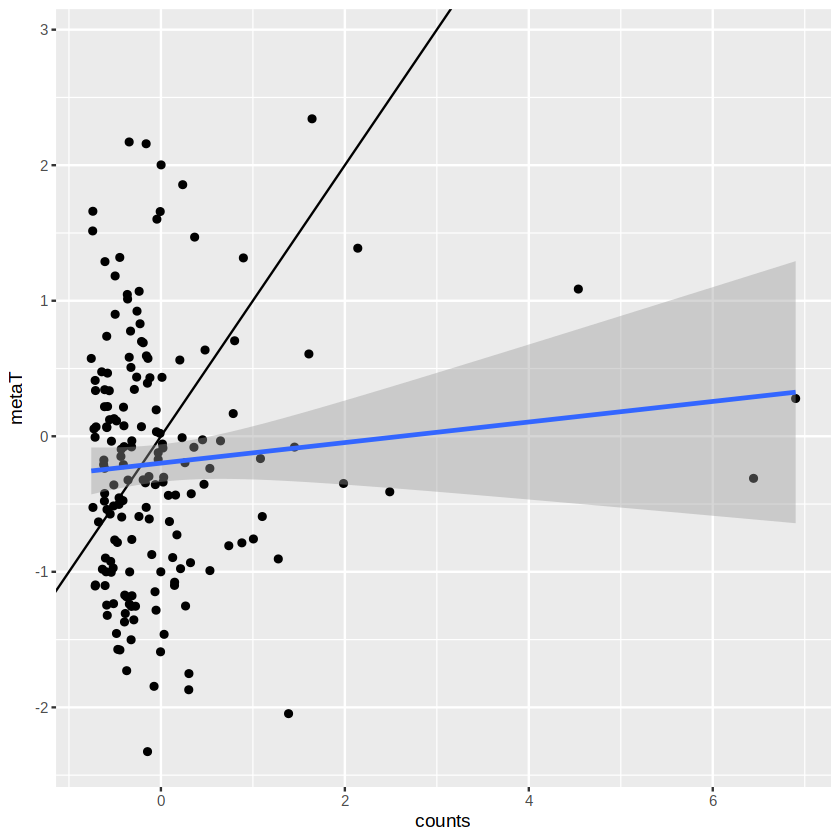

In [21]:
ggplot(summarized_for_test %>% tidyr::pivot_wider(id_cols = c("DateTimeForm"),
                                            names_from=dataset,
                                            values_from=zscore)) + 
    geom_point(aes(x=counts,y=metaT))  +
    geom_abline(aes(intercept=0,slope=1))+
    geom_smooth(aes(x=counts,y=metaT),method="lm")

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 114 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 114 rows containing missing values or values outside the scale range
(`geom_point()`).”


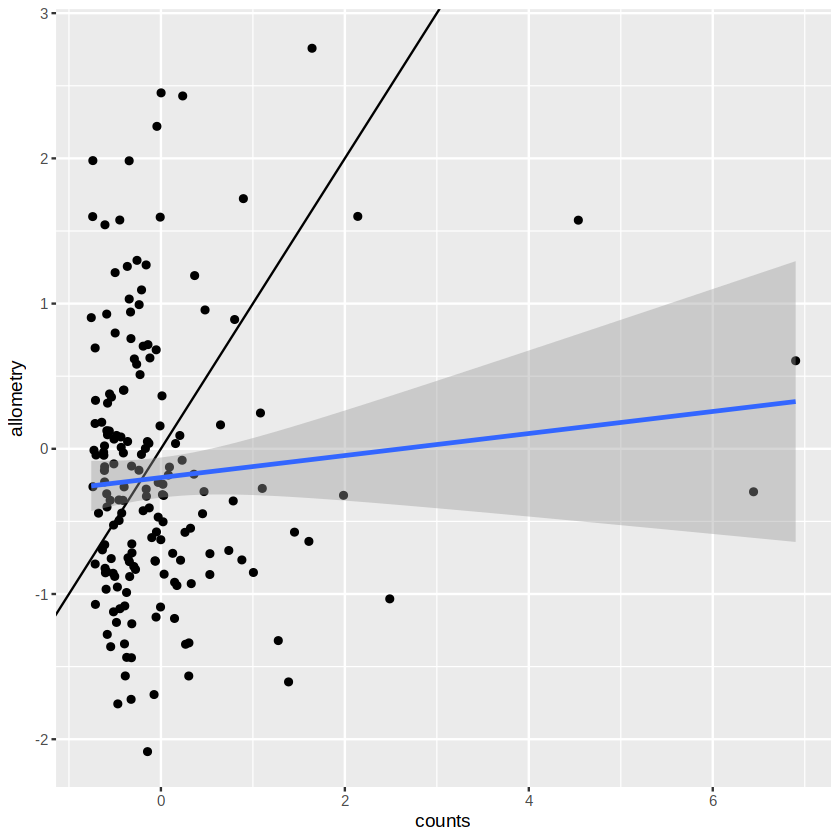

In [22]:
ggplot(summarized_for_test %>% tidyr::pivot_wider(id_cols = c("DateTimeForm"),
                                            names_from=dataset,
                                            values_from=zscore)) + 
    geom_point(aes(x=counts,y=allometry))  +
    geom_abline(aes(intercept=0,slope=1))+
    geom_smooth(aes(x=counts,y=metaT),method="lm")

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_poly_eq()`).”
Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_point()`).”


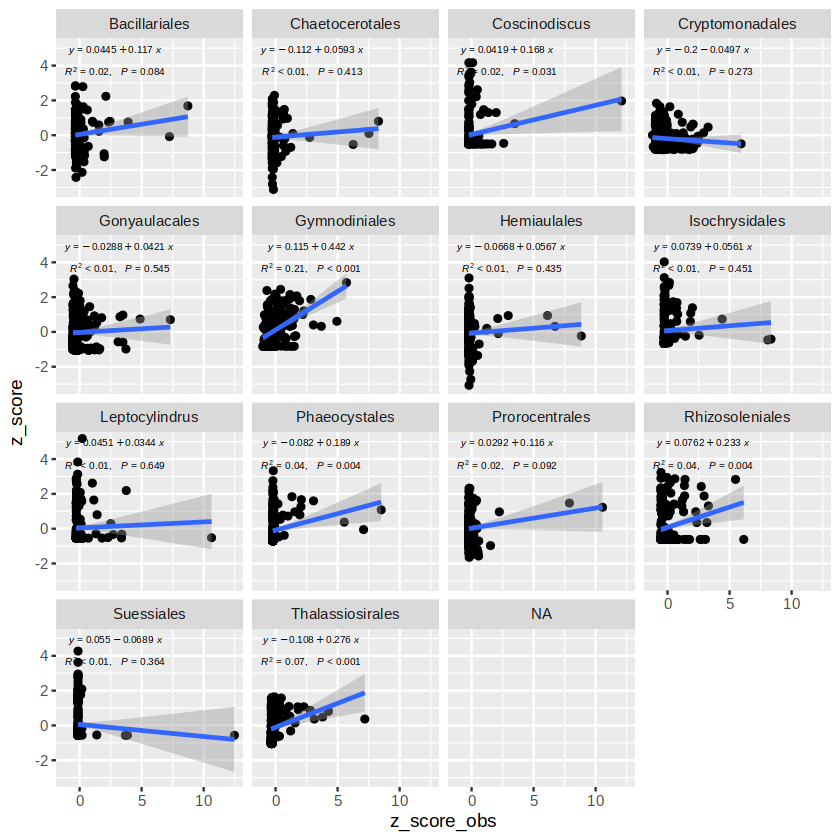

In [23]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type)

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_poly_eq()`).”
Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_point()`).”


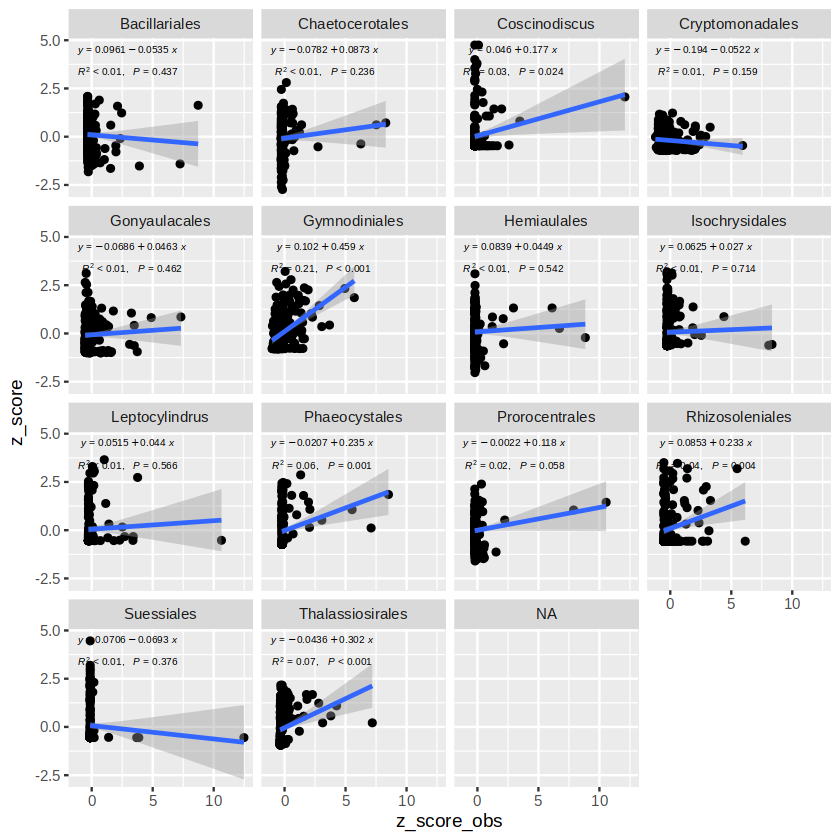

In [24]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_metaT,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type)

Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_line()`).”


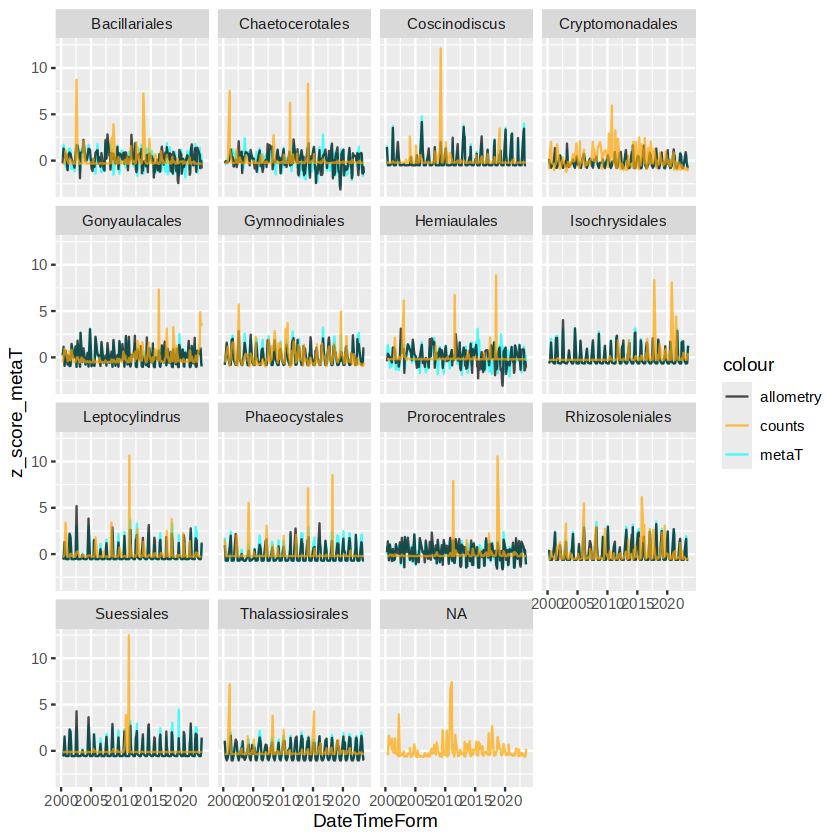

In [25]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_metaT,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::rename(c("abund_metaT"="abund","z_score_metaT"="z_score")) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::rename(c("abund_allometry"="abund","z_score_allometry"="z_score")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_line(aes(x=DateTimeForm,y=z_score_metaT,color="metaT"),alpha=0.7)+
    geom_line(aes(x=DateTimeForm,y=z_score_allometry,color="allometry"),alpha=0.7)+
    geom_line(aes(x=DateTimeForm,y=z_score_obs,color="counts"),alpha=0.7)+
    facet_wrap(~type) + 
    scale_color_manual(values=c("black","orange","cyan"))

Warning message:
“Removed 32 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 32 rows containing missing values or values outside the scale range
(`geom_line()`).”


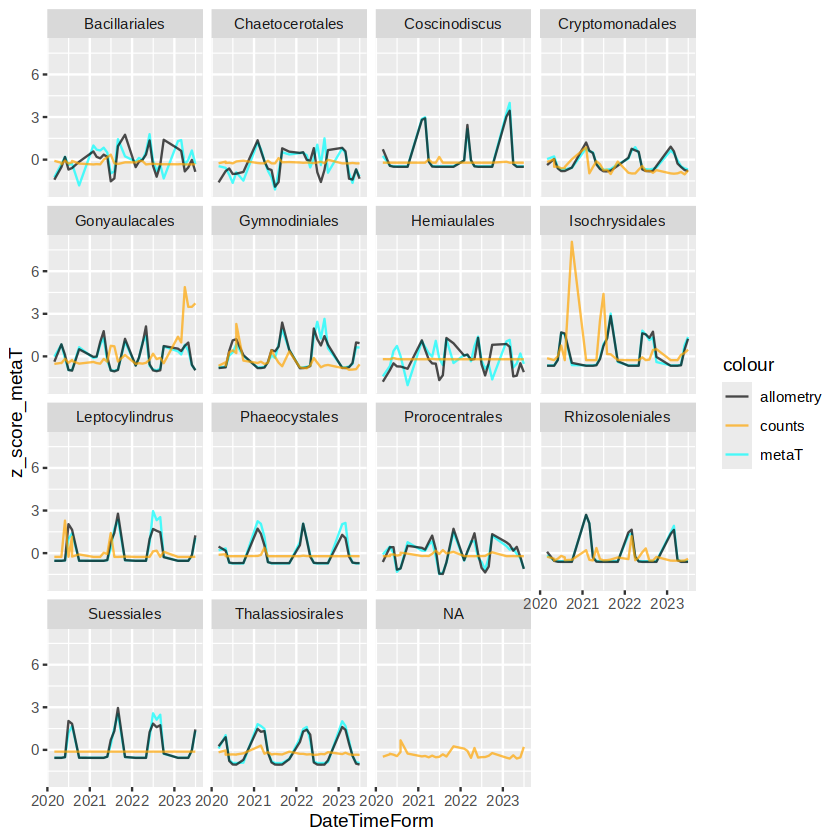

In [26]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_metaT,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::rename(c("abund_metaT"="abund","z_score_metaT"="z_score")) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::rename(c("abund_allometry"="abund","z_score_allometry"="z_score")) %>%
    dplyr::filter(Date>as.Date("2020-03-01",format="%Y-%m-%d")))+
    geom_line(aes(x=DateTimeForm,y=z_score_metaT,color="metaT"),alpha=0.7)+
    geom_line(aes(x=DateTimeForm,y=z_score_allometry,color="allometry"),alpha=0.7)+
    geom_line(aes(x=DateTimeForm,y=z_score_obs,color="counts"),alpha=0.7)+
    facet_wrap(~type) + 
    scale_color_manual(values=c("black","orange","cyan"))

Warning message:
“Removed 41 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 41 rows containing missing values or values outside the scale range
(`geom_line()`).”


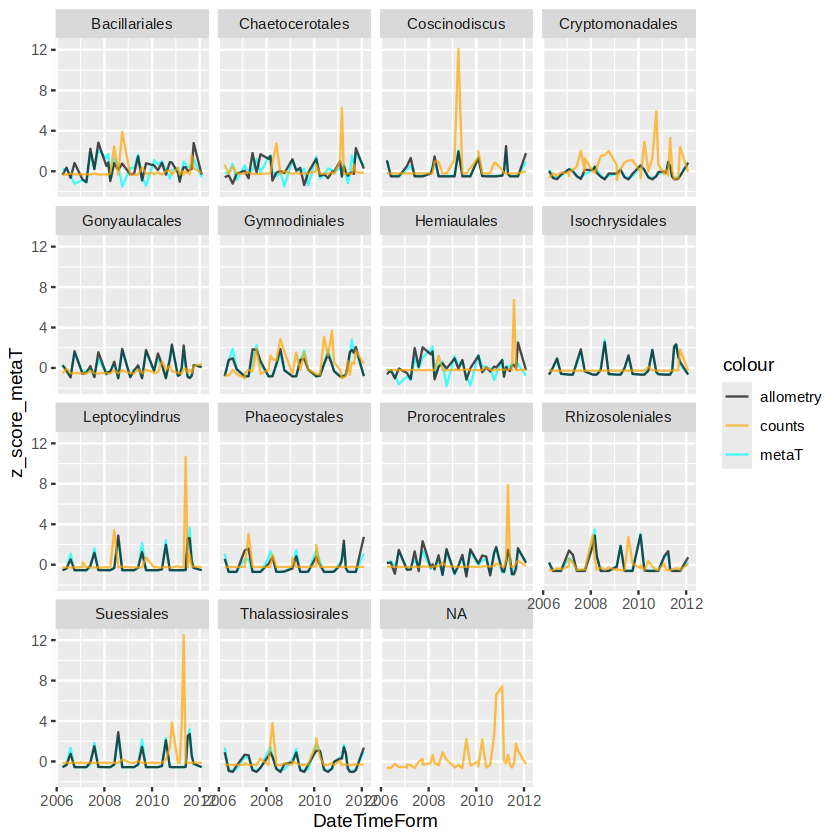

In [27]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_metaT,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::rename(c("abund_metaT"="abund","z_score_metaT"="z_score")) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::rename(c("abund_allometry"="abund","z_score_allometry"="z_score")) %>%
    dplyr::filter((Date>as.Date("2006-03-01",format="%Y-%m-%d"))&
                  (Date<as.Date("2012-03-01",format="%Y-%m-%d"))))+
    geom_line(aes(x=DateTimeForm,y=z_score_metaT,color="metaT"),alpha=0.7)+
    geom_line(aes(x=DateTimeForm,y=z_score_allometry,color="allometry"),alpha=0.7)+
    geom_line(aes(x=DateTimeForm,y=z_score_obs,color="counts"),alpha=0.7)+
    facet_wrap(~type) + 
    scale_color_manual(values=c("black","orange","cyan"))

In [28]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::rename(c("abund_metaT"="abund","z_score_metaT"="z_score")) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::rename(c("abund_allometry"="abund","z_score_allometry"="z_score")) %>%
    dplyr::filter((Date>as.Date("2000-03-01",format="%Y-%m-%d"))&
                  (Date<as.Date("2003-03-01",format="%Y-%m-%d"))))+
    geom_line(aes(x=DateTimeForm,y=z_score_metaT,color=type),alpha=0.7)

ERROR: [1m[33mError[39m in `dplyr::left_join()`:[22m
[1m[22m[33m![39m Join columns in `y` must be present in the data.
[31m✖[39m Problem with `DateTimeForm` and `taxon`.


In [ ]:
for_spearman = for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d"))
spearman_or_pearson="pearson"
spearman_boot <- function(data, indices) {
  d <- data[indices, ] # allows boot to select sample
  return(cor(d[,1], d[,2], method = spearman_or_pearson))
}

results_fr = data.frame()
for (taxon in unique(for_spearman$type)) {
    if (is.na(taxon)) {
        next
    }
    for_spearman_sub = for_spearman %>% dplyr::filter(type==taxon)
    spearman_test = cor.test(for_spearman_sub$abund, for_spearman_sub$Group_Ct, method = spearman_or_pearson)
    rho_val = spearman_test$estimate
    p_val = spearman_test$p.value
    
    df_for_boot <- data.frame(for_spearman_sub$abund, for_spearman_sub$Group_Ct)
    boot <- boot(data = df_for_boot, statistic = spearman_boot, R = 1000)
    conf_interval <- boot.ci(boot, type = "perc")
    
    results_fr = results_fr %>%
        dplyr::bind_rows(data.frame("taxon"=taxon,
                                    "rho"=rho_val,
                                    "rho_lower"=conf_interval$percent[4],
                                    "rho_upper"=conf_interval$percent[5],
                                    "pval"=p_val,
                                    "dataset"="allometry"))
}
results_fr$pval_adj = p.adjust(results_fr$pval, method = "BH", n = length(results_fr$pval))

In [ ]:
for_spearman = for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_metaT,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d"))

spearman_boot <- function(data, indices) {
  d <- data[indices, ] # allows boot to select sample
  return(cor(d[,1], d[,2], method = spearman_or_pearson))
}

results_fr_2 = data.frame()
for (taxon in unique(for_spearman$type)) {
    if (is.na(taxon)) {
        next
    }
    for_spearman_sub = for_spearman %>% dplyr::filter(type==taxon)
    spearman_test = cor.test(for_spearman_sub$abund, for_spearman_sub$Group_Ct, method = spearman_or_pearson)
    rho_val = spearman_test$estimate
    p_val = spearman_test$p.value
    
    df_for_boot <- data.frame(for_spearman_sub$abund, for_spearman_sub$Group_Ct)
    boot <- boot(data = df_for_boot, statistic = spearman_boot, R = 1000)
    conf_interval <- boot.ci(boot, type = "bca")
    
    results_fr_2 = results_fr_2 %>%
        dplyr::bind_rows(data.frame("taxon"=taxon,
                                    "rho"=rho_val,
                                    "rho_lower"=conf_interval$bca[4],
                                    "rho_upper"=conf_interval$bca[5],
                                    "pval"=p_val,
                                    "dataset"="metaT"))
}

results_fr_2$pval_adj = p.adjust(results_fr_2$pval, method = "BH",
                                 n = length(results_fr_2$pval))

results_fr = results_fr %>% dplyr::bind_rows(results_fr_2)

In [31]:
## see whether difference is significant!
for_spearman_allometry = for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d"))

for_spearman_metaT = for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_metaT,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d"))

spearman_or_pearson="pearson"
spearman_boot <- function(data, indices) {
  d <- data[indices, ] # allows boot to select sample
  return(cor(d[,1], d[,2], method = spearman_or_pearson))
}

spearman_boot_diff <- function(data, indices) {
  d <- data[indices, ] # allows boot to select sample
  corr_allom <- cor(as.numeric(d$allometry), as.numeric(d$Group_Ct), method = spearman_or_pearson)
  corr_metaT <- cor(as.numeric(d$metaT), as.numeric(d$Group_Ct), method = spearman_or_pearson)
    
  return(corr_allom - corr_metaT)
}

results_fr = data.frame()
results_differences = data.frame()
for (taxon in unique(for_spearman_allometry$type)) {
    if (is.na(taxon)) {
        next
    }
    for_spearman_sub_allom = for_spearman_allometry %>% dplyr::filter(type==taxon)
    for_spearman_sub_metaT = for_spearman_metaT %>% dplyr::filter(type==taxon)
    spearman_test_allom = cor.test(for_spearman_sub_allom$abund, for_spearman_sub_allom$Group_Ct, 
                             method = spearman_or_pearson)
    spearman_test_metaT = cor.test(for_spearman_sub_metaT$abund, for_spearman_sub_metaT$Group_Ct, 
                             method = spearman_or_pearson)
    
    rho_val_allom = spearman_test_allom$estimate
    p_val_allom = spearman_test_allom$p.value
    rho_val_metaT = spearman_test_metaT$estimate
    p_val_metaT = spearman_test_metaT$p.value
    
    ## bootstrapped interval for allometry
    df_for_boot <- data.frame(for_spearman_sub_allom$abund, for_spearman_sub_allom$Group_Ct)
    boot <- boot(data = df_for_boot, statistic = spearman_boot, R = 1000)
    conf_interval_allom <- boot.ci(boot, type = c("perc","bca"))
    
    ## bootstrapped interval for metaT
    df_for_boot <- data.frame(for_spearman_sub_metaT$abund, for_spearman_sub_metaT$Group_Ct)
    boot <- boot(data = df_for_boot, statistic = spearman_boot, R = 1000)
    conf_interval_metaT <- boot.ci(boot, type = c("perc","bca"))
    
    ## bootstrapped differences between the two
    df_for_boot <- data.frame("allometry"=for_spearman_sub_allom$abund, 
                              "metaT"=for_spearman_sub_metaT$abund, 
                              "Group_Ct"=for_spearman_sub_metaT$Group_Ct)
    boot <- boot(data = df_for_boot, statistic = spearman_boot_diff, R = 1000)
    conf_interval_differences <- boot.ci(boot, type = c("perc","bca"))
    
    results_fr = results_fr %>%
        dplyr::bind_rows(data.frame("taxon"=taxon,
                                    "rho"=rho_val_allom,
                                    "rho_lower"=conf_interval_allom$percent[4],
                                    "rho_upper"=conf_interval_allom$percent[5],
                                    "rho_lower_bca"=conf_interval_differences$bca[4],
                                    "rho_upper_bca"=conf_interval_differences$bca[5],
                                    "pval"=p_val_allom,
                                    "dataset"="allometry"))%>%
        dplyr::bind_rows(data.frame("taxon"=taxon,
                                    "rho"=rho_val_metaT,
                                    "rho_lower"=conf_interval_metaT$percent[4],
                                    "rho_upper"=conf_interval_metaT$percent[5],
                                    "rho_lower_bca"=conf_interval_differences$bca[4],
                                    "rho_upper_bca"=conf_interval_differences$bca[5],
                                    "pval"=p_val_metaT,
                                    "dataset"="metaT"))
    
    results_differences = results_differences %>%
        dplyr::bind_rows(data.frame("taxon"=taxon,
                                    "difference"=rho_val_allom-rho_val_metaT,
                                    "rho_lower"=conf_interval_differences$percent[4],
                                    "rho_upper"=conf_interval_differences$percent[5],
                                    "rho_lower_bca"=conf_interval_differences$bca[4],
                                    "rho_upper_bca"=conf_interval_differences$bca[5]))
        
}
results_fr$pval_adj = p.adjust(results_fr$pval, method = "BH", n = length(results_fr$pval))

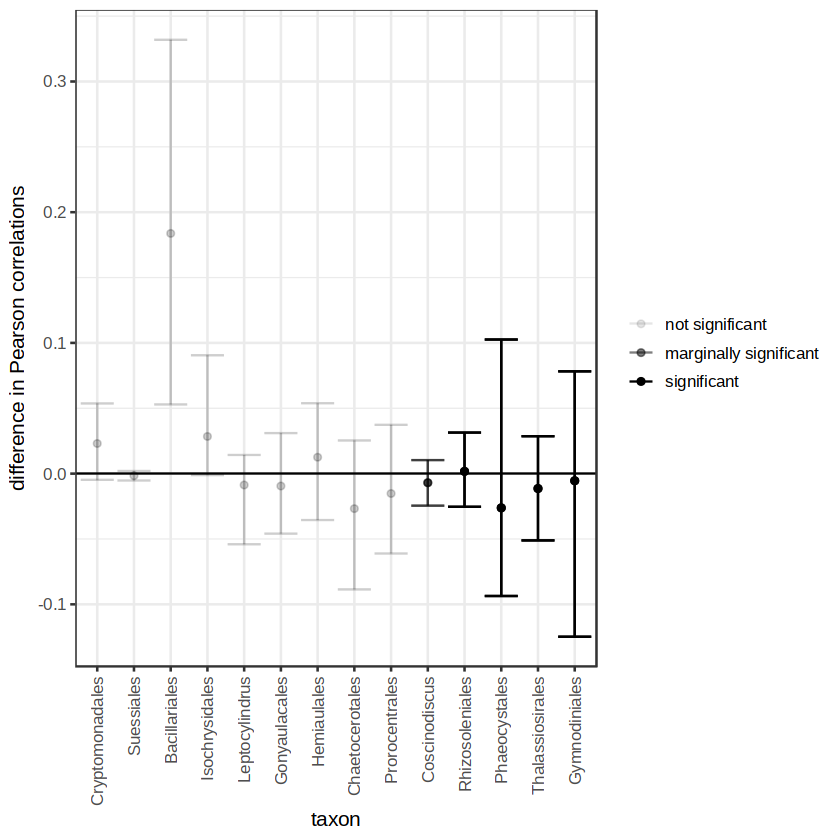

In [32]:
ggplot(results_differences %>% dplyr::left_join(results_fr%>%
                                                dplyr::select(taxon,pval_adj,dataset,rho),by="taxon") %>%
    dplyr::mutate(pval_sig = case_when(pval_adj < 0.05 ~ "significant",
                                       pval_adj < 0.10 ~ "marginally significant",
                                      TRUE ~ "not significant")) %>%
    dplyr::arrange(rho)) + 
    geom_point(aes(y=difference,x=factor(taxon,levels=unique(taxon)),alpha=pval_sig))+ 
    geom_errorbar(aes(ymin=rho_lower_bca,ymax=rho_upper_bca,x=taxon,alpha=pval_sig))+
    scale_alpha_manual(values=c(0.1,0.5,1),breaks=c("not significant",
                                                    "marginally significant",
                                                    "significant"),
                       name="") + theme_bw(base_size=12) + xlab("taxon") + 
    ylab("difference in Pearson correlations") + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    geom_hline(aes(yintercept=0))

#ggsave("../figures/difference_in_pearson.pdf")
    

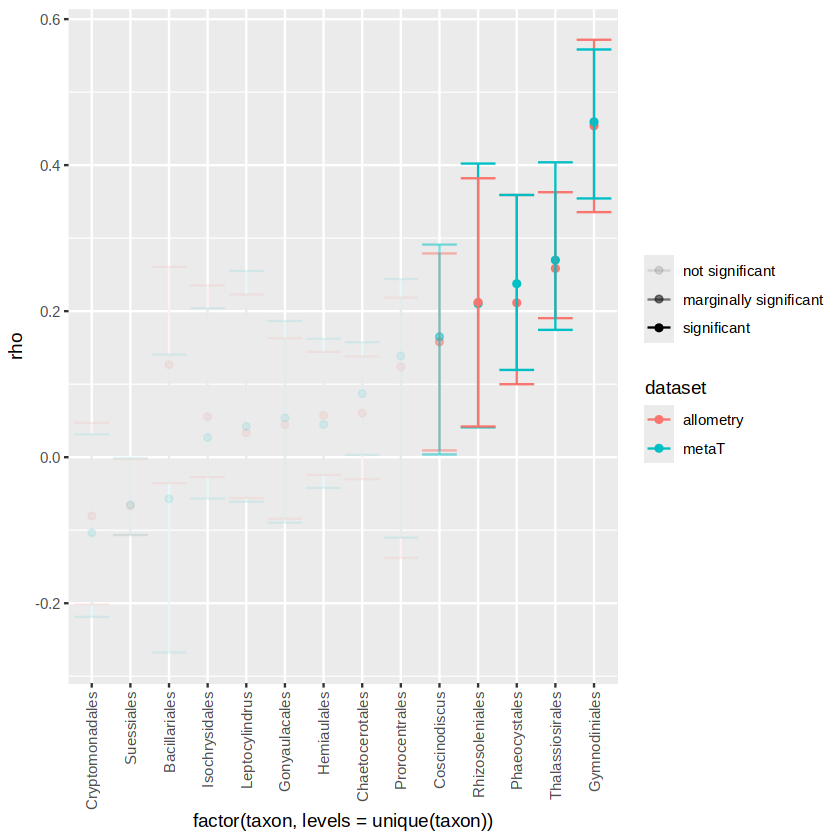

In [33]:
ggplot(results_fr %>%
    dplyr::mutate(pval_sig = case_when(pval_adj < 0.05 ~ "significant",
                                       pval_adj < 0.10 ~ "marginally significant",
                                      TRUE ~ "not significant")) %>%
    dplyr::arrange(rho)) + 
    geom_point(aes(y=rho,x=factor(taxon,levels=unique(taxon)),color=dataset,alpha=pval_sig))+ 
    geom_errorbar(aes(ymin=rho_lower,ymax=rho_upper,x=taxon,color=dataset,alpha=pval_sig))+
    scale_alpha_manual(values=c(0.1,0.5,1),breaks=c("not significant",
                                                    "marginally significant",
                                                    "significant"),
                       name="") + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

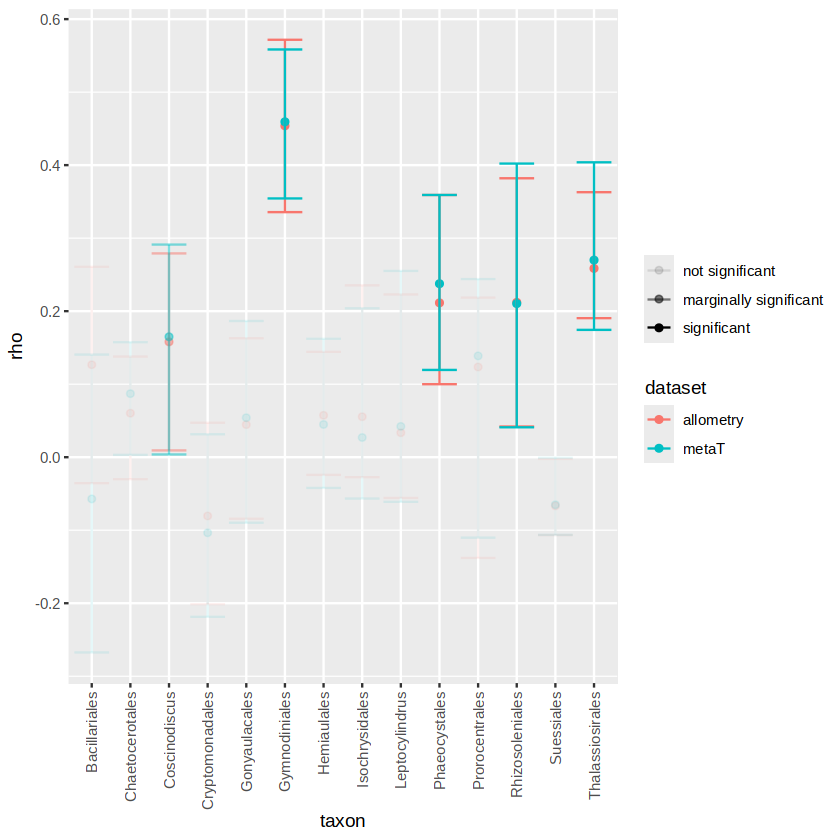

In [34]:
ggplot(results_fr %>%
    dplyr::mutate(pval_sig = case_when(pval_adj < 0.05 ~ "significant",
                                       pval_adj < 0.10 ~ "marginally significant",
                                      TRUE ~ "not significant"))) + 
    geom_point(aes(y=rho,x=taxon,color=dataset,alpha=pval_sig))+ 
    geom_errorbar(aes(ymin=rho_lower,ymax=rho_upper,x=taxon,color=dataset,alpha=pval_sig))+
    scale_alpha_manual(values=c(0.1,0.5,1),breaks=c("not significant",
                                                    "marginally significant",
                                                    "significant"),
                       name="") + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

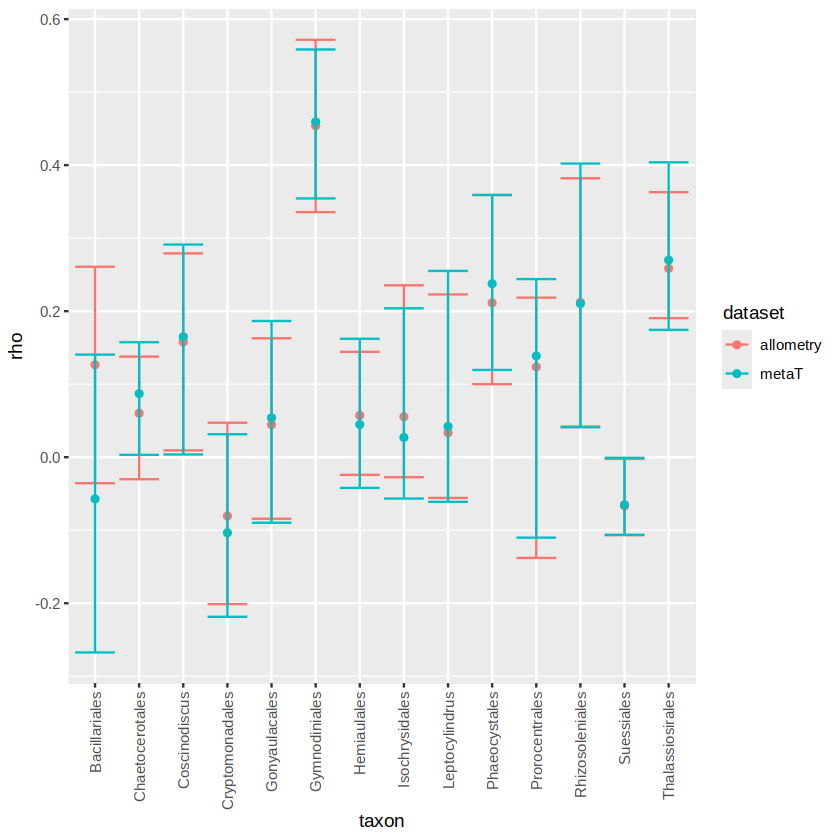

In [35]:
ggplot(results_fr) + 
    geom_point(aes(y=rho,x=taxon,color=dataset))+ 
    geom_errorbar(aes(ymin=rho_lower,ymax=rho_upper,x=taxon,color=dataset))+ 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

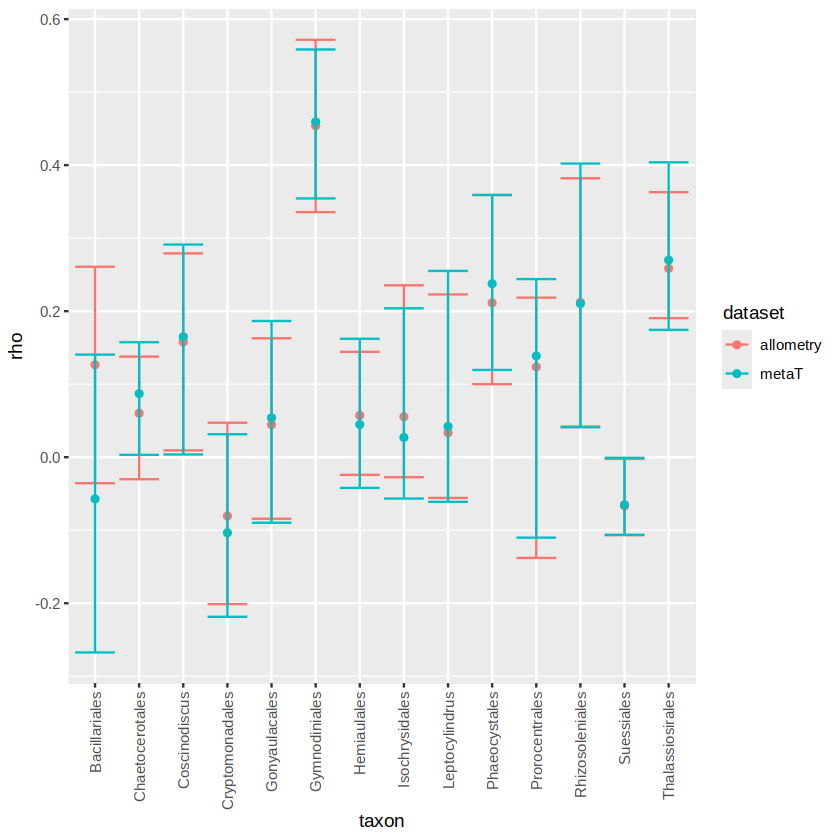

In [36]:
ggplot(results_fr) + 
    geom_point(aes(y=rho,x=taxon,color=dataset))+ 
    geom_errorbar(aes(ymin=rho_lower,ymax=rho_upper,x=taxon,color=dataset))+ 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

Saving 7 x 7 in image


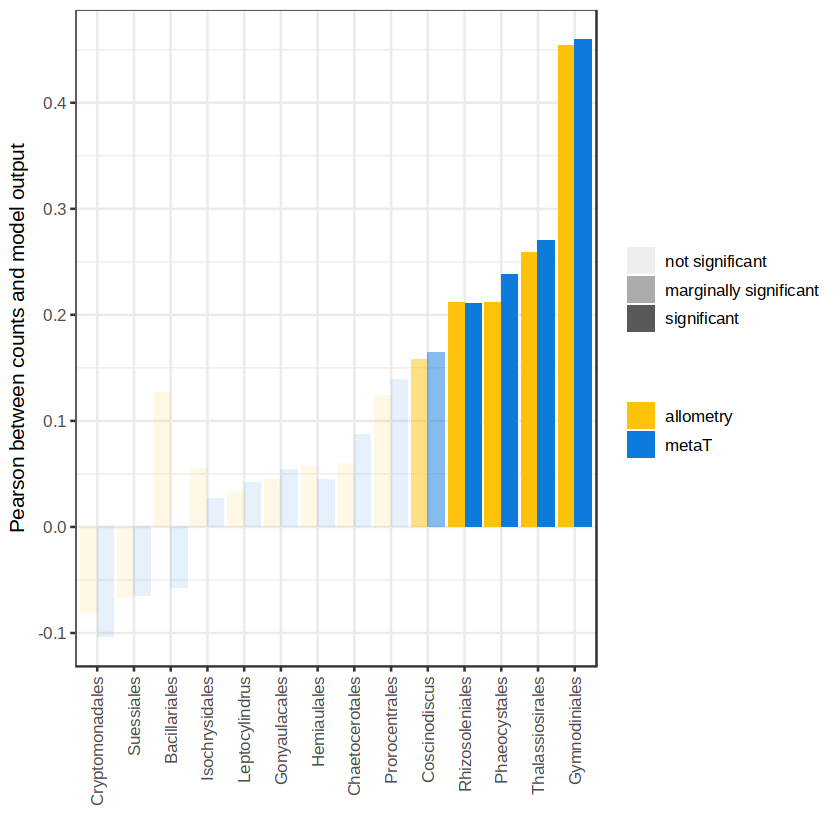

In [37]:
for_bar = results_fr %>% dplyr::arrange(taxon,desc(rho)) %>% 
    dplyr::mutate(rho_sig = case_when(pval_adj > 0.1 ~ 0,
                                      TRUE ~ rho)) %>%
    dplyr::mutate(pval_sig = case_when(pval_adj < 0.05 ~ "significant",
                                       pval_adj < 0.10 ~ "marginally significant",
                                      TRUE ~ "not significant")) %>%
    dplyr::arrange(rho) 

ggplot(for_bar) + 
    geom_bar(aes(x=factor(taxon,levels=unique(taxon)),
                 y=rho,alpha=pval_sig,
                 fill=dataset,group=dataset),
             stat="identity",position="dodge")+  
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))+
    scale_alpha_manual(values=c(0.1,0.5,1),breaks=c("not significant",
                                                    "marginally significant",
                                                    "significant"),
                       name="") + 
    scale_fill_manual(values=c("#FFC20A","#0C7BDC"),name="") + 
    xlab("") + ylab("Pearson between counts and model output")

ggsave("../figures/pearson_corr_obs_revise.pdf")

In [38]:
for_bar

,taxon,rho,rho_lower,rho_upper,rho_lower_bca,rho_upper_bca,pval,dataset,pval_adj,rho_sig,pval_sig
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<chr>
cor...1,Cryptomonadales,-0.10352544,-0.218601507,0.0313971258,-0.004756735,0.053697763,1.585432e-01,metaT,3.170864e-01,0.0000000,not significant
cor...2,Cryptomonadales,-0.08048729,-0.201260242,0.0471986261,-0.004756735,0.053697763,2.734970e-01,allometry,4.786198e-01,0.0000000,not significant
cor...3,Suessiales,-0.06668909,-0.106712201,-0.0024071250,-0.005259865,0.002024701,3.644836e-01,allometry,5.628837e-01,0.0000000,not significant
cor...4,Suessiales,-0.06508908,-0.106375697,-0.0007559051,-0.005259865,0.002024701,3.761294e-01,metaT,5.628837e-01,0.0000000,not significant
cor...5,Bacillariales,-0.05713573,-0.267376680,0.1405033848,0.052924634,0.331880349,4.373268e-01,metaT,5.628837e-01,0.0000000,not significant
cor...6,Isochrysidales,0.02697789,-0.056647242,0.2039309982,-0.001140635,0.090551094,7.139844e-01,metaT,7.139844e-01,0.0000000,not significant
cor...7,Leptocylindrus,0.03350105,-0.055766385,0.2229260873,-0.054060019,0.014267586,6.489826e-01,allometry,6.730190e-01,0.0000000,not significant
cor...8,Leptocylindrus,0.04220180,-0.061112482,0.2551116729,-0.054060019,0.014267586,5.663150e-01,metaT,6.098777e-01,0.0000000,not significant
cor...9,Gonyaulacales,0.04458673,-0.084270292,0.1629028977,-0.045899621,0.030996145,5.445628e-01,allometry,6.098777e-01,0.0000000,not significant


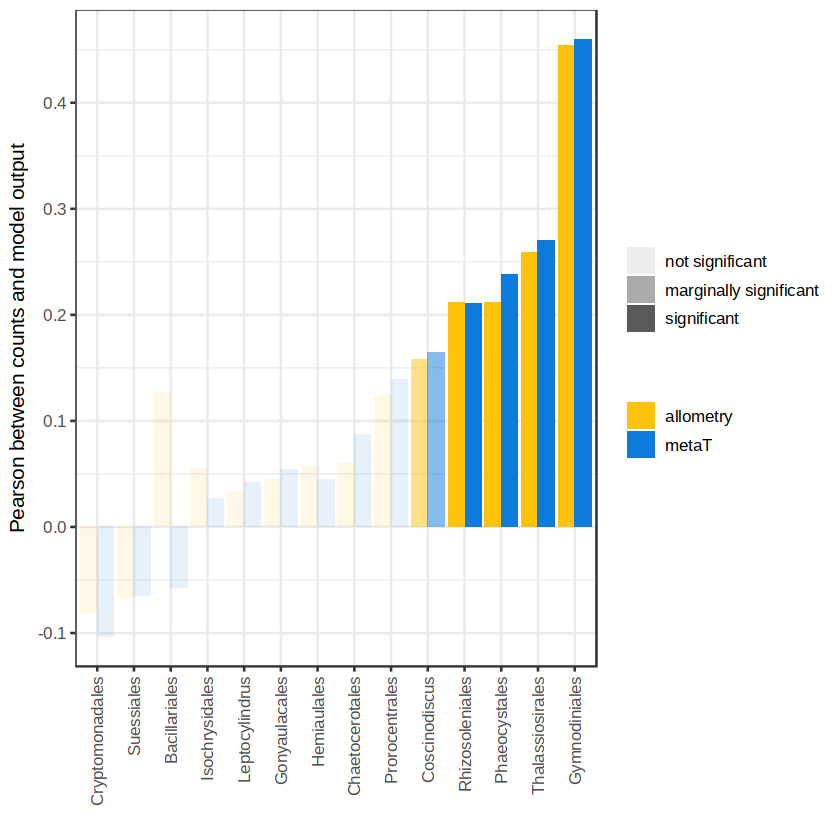

In [51]:
for_bar = results_fr %>% dplyr::arrange(taxon,desc(rho)) %>% 
    dplyr::mutate(rho_sig = case_when(pval_adj > 0.1 ~ 0,
                                      TRUE ~ rho)) %>%
    dplyr::mutate(pval_sig = case_when(pval_adj < 0.05 ~ "significant",
                                       pval_adj < 0.10 ~ "marginally significant",
                                      TRUE ~ "not significant")) %>%
    dplyr::arrange(rho) 

ggplot(for_bar) + 
    geom_bar(aes(x=factor(taxon,levels=unique(taxon)),
                 y=rho,alpha=pval_sig,
                 fill=dataset,group=dataset),
             stat="identity",position="dodge")+  
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))+
    scale_alpha_manual(values=c(0.1,0.5,1),breaks=c("not significant",
                                                    "marginally significant",
                                                    "significant"),
                       name="") + 
    scale_fill_manual(values=c("#FFC20A","#0C7BDC"),name="") + 
    xlab("") + ylab("Pearson between counts and model output")

#ggsave("../figures/pearson_corr_obs.pdf")

In [40]:
for_bar %>% dplyr::select(taxon,rho,pval_adj,pval_sig,dataset) %>%
    dplyr::arrange(taxon)

,taxon,rho,pval_adj,pval_sig,dataset
,<chr>,<dbl>,<dbl>,<chr>,<chr>
cor...1,Bacillariales,-0.05713573,5.628837e-01,not significant,metaT
cor...2,Bacillariales,0.12661183,1.965013e-01,not significant,allometry
cor...3,Chaetocerotales,0.06025952,5.628837e-01,not significant,allometry
cor...4,Chaetocerotales,0.08704308,4.408872e-01,not significant,metaT
cor...5,Coscinodiscus,0.15797867,8.628941e-02,marginally significant,allometry
cor...6,Coscinodiscus,0.16494889,7.488766e-02,marginally significant,metaT
cor...7,Cryptomonadales,-0.10352544,3.170864e-01,not significant,metaT
cor...8,Cryptomonadales,-0.08048729,4.786198e-01,not significant,allometry
cor...9,Gonyaulacales,0.04458673,6.098777e-01,not significant,allometry


`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 187 rows containing non-finite outside the scale range
(`stat_poly_eq()`).”
Warning message:
“Removed 187 rows containing missing values or values outside the scale range
(`geom_point()`).”


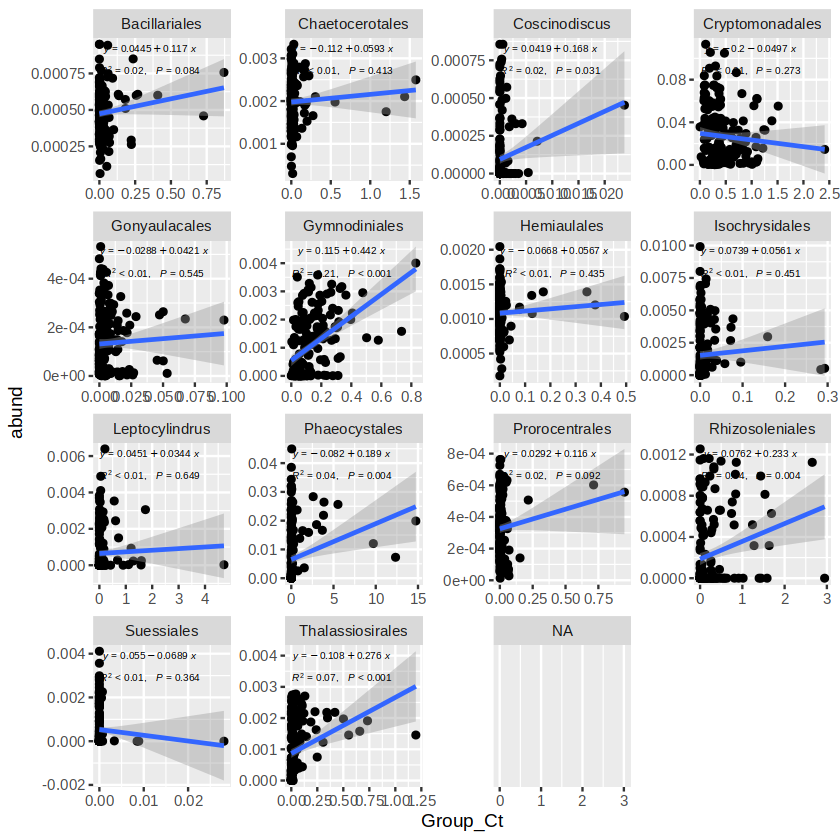

In [41]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=Group_Ct,y=abund))+
    geom_smooth(aes(x=Group_Ct,y=abund,group=type),method="lm")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type,scales="free")

In [42]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type)

ERROR: [1m[33mError[39m in `dplyr::left_join()`:[22m
[1m[22m[33m![39m Join columns in `y` must be present in the data.
[31m✖[39m Problem with `DateTimeForm` and `taxon`.


In [ ]:
ggplot(for_prob_test%>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type)

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


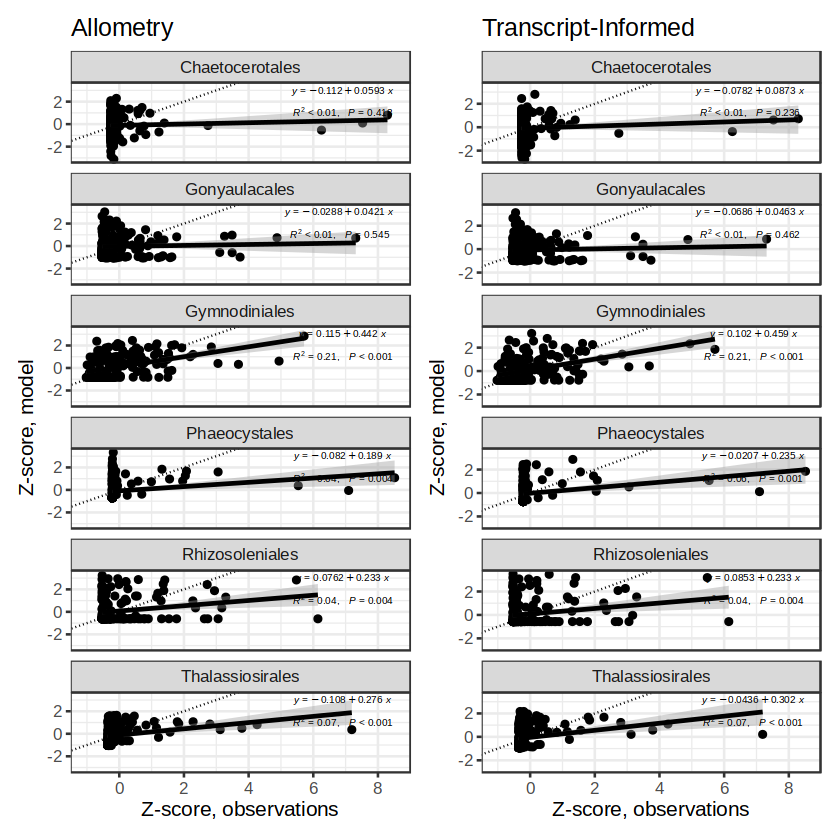

In [45]:
allometry=ggplot(for_prob_test%>%
    dplyr::filter(type %in% c("Chaetocerotales","Coscinodiscales",
                              "Gonyaulacales","Gymnodiniales",
                              "Phaeocystales","Rhizosoleniales",
                              "Thalassiosirales")) %>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_allometry,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm",color="black")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   size=2,
                   label.x = "right",
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type,ncol=1) + theme_bw(base_size=12) + 
    geom_abline(aes(intercept=0,slope=1),linetype="dotted")+
    ylab("Z-score, model") + xlab("Z-score, observations") + 
    ggtitle("Allometry")

metaT=ggplot(for_prob_test%>%
    dplyr::filter(type %in% c("Chaetocerotales","Coscinodiscales",
                              "Gonyaulacales","Gymnodiniales",
                              "Phaeocystales","Rhizosoleniales",
                              "Thalassiosirales")) %>%
    dplyr::group_by(type) %>%
    dplyr::mutate(z_score_obs=(Group_Ct-mean(Group_Ct))/sd(Group_Ct)) %>%
    dplyr::mutate(DateTimeForm=as.Date(paste0(format(as.Date(Date,format="%Y-%m-%d"), 
                                                     "%Y-%m"), "-01"))) %>%
    dplyr::left_join(infill_dates_metaT,by=c("DateTimeForm","type"="taxon")) %>%
    dplyr::filter(Date>as.Date("2000-03-01",format="%Y-%m-%d")))+
    geom_point(aes(x=z_score_obs,y=z_score))+
    geom_smooth(aes(x=z_score_obs,y=z_score,group=type),method="lm",color="black")+
    stat_poly_eq(aes(label = paste("atop(", after_stat(eq.label), 
                      ", paste(", after_stat(rr.label), 
                      "*\", \"~~", after_stat(p.value.label), "))"),
                   x=z_score_obs,y=z_score), 
                   label.x = "right",
                   size=2,
                   formula = y ~ x, 
                   parse = TRUE) + 
    facet_wrap(~type,ncol=1) + theme_bw(base_size=12) + 
    geom_abline(aes(intercept=0,slope=1),linetype="dotted")+
    ylab("Z-score, model") + xlab("Z-score, observations") + 
    ggtitle("Transcript-Informed")

combo_plot = allometry | metaT
combo_plot
ggsave(plot=combo_plot+plot_annotation(tag_levels = 'A'),width=9,height=10,units="in",filename="../figures/combined_model_results_3.pdf")

In [74]:
bacillariales_events = for_prob_test %>% dplyr::filter(type=="Bacillariales") %>%
    dplyr::mutate(high_event=case_when(Group_Ct > 0.05~"high",
                  TRUE~"low"),
                 year=year(Date)) %>%
    dplyr::filter(year>2007)%>%
    dplyr::group_by(high_event,year) %>% dplyr::tally() %>%
    dplyr::arrange(year) %>% tidyr::pivot_wider(id_cols = c("year"),
                                         names_from="high_event",
                                         values_from="n") %>%
    dplyr::mutate(high=case_when(is.na(high)~0,
                                 TRUE~high))

mk.test(bacillariales_events$high)


	Mann-Kendall trend test

data:  bacillariales_events$high
z = -2.1938, n = 16, p-value = 0.02825
alternative hypothesis: true S is not equal to 0
sample estimates:
          S        varS         tau 
-47.0000000 439.6666667  -0.4547914 


In [75]:
thalassiosirales_events = for_prob_test %>% dplyr::filter(type=="Thalassiosirales") %>%
    dplyr::mutate(high_event=case_when(Group_Ct > 0.25~"high",
                  TRUE~"low"),
                 year=year(Date)) %>%
    dplyr::group_by(high_event,year) %>% dplyr::tally() %>%
    dplyr::arrange(year) %>% tidyr::pivot_wider(id_cols = c("year"),
                                         names_from="high_event",
                                         values_from="n") %>%
    dplyr::mutate(high=case_when(is.na(high)~0,
                                 TRUE~high))

mk.test(thalassiosirales_events$high,alternative = "less")


	Mann-Kendall trend test

data:  thalassiosirales_events$high
z = -1.9872, n = 24, p-value = 0.02345
alternative hypothesis: true S is less than 0
sample estimates:
          S        varS         tau 
-61.0000000 911.6666667  -0.3454109 


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type and Date.
ℹ Output is grouped by type.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(type, Date))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


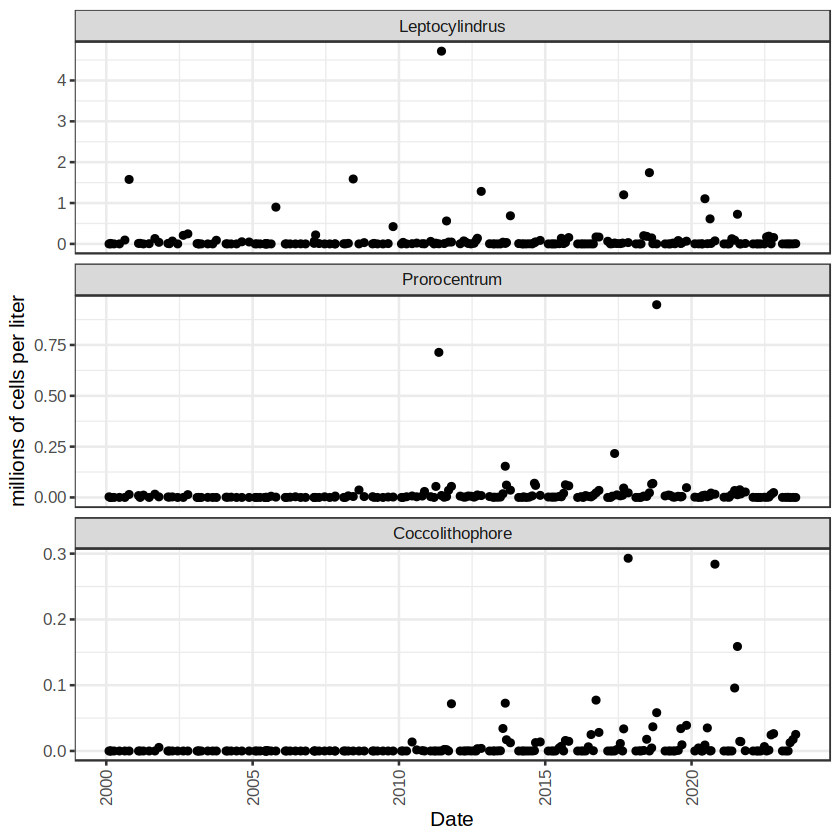

In [9]:
for_plotting = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus")) %>%
    dplyr::group_by(type,Date) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore")))) + 
    geom_point(aes(x=Date,y=Group_Ct)) + 
    theme_bw(base_size=12) + facet_wrap(~type,nrow=3,scales="free_y") +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends